# assignment 1: white hat / black hat

both charts use the same data, millet prices in burkina faso from the wfp

- white hat: millet costs almost twice as much as in 2015
- black hat: "prices up 158% in five years". the numbers are true but the overall message is misleading and dramatic

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

data = pd.read_csv("../clean/market_month_full.csv")
millet = data[(data.iso3 == "BFA") & (data.food == "millet")]

# median price of all markets per month
monthly = millet.groupby("month").price_lcu.median()
monthly.index = pd.to_datetime(monthly.index)
yearly = millet.groupby("year").price_lcu.median()
monthly.head()

month
2015-01-01    173.5
2015-02-01    175.0
2015-03-01    175.0
2015-04-01    179.0
2015-05-01    189.0
Name: price_lcu, dtype: float64

## white hat

all 10 years, y axis starts at 0, and the note at the bottom says what the data is and what it leaves out

In [ ]:
plt.figure(figsize=(10, 5))
# grey = june-september each year, the months before the harvest when prices go up
for y in range(2015, 2025):
    plt.axvspan(pd.Timestamp(f"{y}-06-01"), pd.Timestamp(f"{y}-09-30"), color="lightgrey", alpha=0.5, linewidth=0,
                label="before harvest (Jun-Sep)" if y == 2015 else None)
plt.plot(monthly, label="monthly median price of all markets")
# dashed = yearly median, drawn in the middle of each year, shows the long-term rise without the zigzag
plt.plot(pd.to_datetime(yearly.index.astype(str) + "-07-01"), yearly, "k--", linewidth=1.2, label="yearly median")
plt.ylim(0, 500)
plt.title("Millet prices in Burkina Faso, 2015-2024")
plt.ylabel("price (CFA francs per kg)")
plt.xlabel("year")
low, high = monthly.idxmin(), monthly.idxmax()
line = dict(arrowstyle="-", color="grey")
plt.annotate(f"lowest: {monthly.min():.0f} ({low:%b %Y})", (low, monthly.min()), xytext=(low, 100), ha="center", arrowprops=line)
plt.annotate(f"highest: {monthly.max():.0f} ({high:%b %Y})", (high, monthly.max()), xytext=(pd.Timestamp("2023-06-01"), 460), ha="center", arrowprops=line)
plt.annotate("2021-2022: biggest jump,\nprices almost double", (pd.Timestamp("2022-03-01"), 330),
             xytext=(pd.Timestamp("2020-06-01"), 420), ha="center", arrowprops=line)
plt.legend(loc="upper left")
plt.grid(alpha=0.3)
plt.figtext(0.01, 0.01, "Source: WFP food prices (HDX). Retail prices from 52-61 markets, not adjusted for inflation. "
            "Prices rise every year before the harvest (Jun-Sep).", fontsize=8)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig("white_hat.png", dpi=300)
plt.show()

## black hat

Every year, the prices of millet increase before harves and decrease after (basic seasonal supply and demand). But the trend line hides the cyclical nature of the data and makes it seem like one smoot increase. The chart does not include the drop in 2023. The y axis starts at 150 to make the rise look bigger. The chart only shows the data from the cheapest month (October 2019) to the most expensive one (September 2024) for dramatic effect. The title has a scary number and no mention of seasons or inflation.

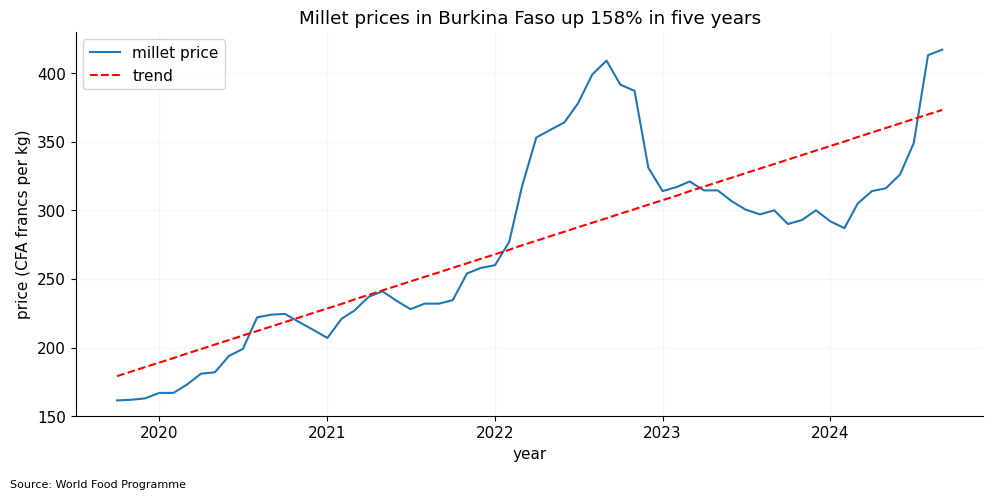

In [11]:
window = monthly[monthly.idxmin():monthly.idxmax()]
change = (window.iloc[-1] / window.iloc[0] - 1) * 100
x = np.arange(len(window))
trend = np.polyval(np.polyfit(x, window.values, 1), x)

plt.figure(figsize=(10, 5))
plt.plot(window, label="millet price")
plt.plot(window.index, trend, "r--", label="trend")
plt.ylim(150, 430)
plt.text(window.index[6], 385, f"+{change:.0f}%", fontsize=34, fontweight="bold", color="red")
plt.title(f"Millet prices in Burkina Faso up {change:.0f}% in five years")
plt.ylabel("price (CFA francs per kg)")
plt.xlabel("year")
plt.legend()
plt.grid(alpha=0.3)
plt.figtext(0.01, 0.01, "Source: World Food Programme", fontsize=8)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig("black_hat.png", dpi=300)
plt.show()

The +158% is real, but it depends a lot on where you start. 2019 was an unusually cheap year

In [12]:
print(f"white hat: yearly median 2015 {yearly[2015]:.0f} -> 2024 {yearly[2024]:.0f} (+{(yearly[2024] / yearly[2015] - 1) * 100:.0f}%)")
print(f"black hat: {window.index[0]:%b %Y} {window.iloc[0]:.0f} -> {window.index[-1]:%b %Y} {window.iloc[-1]:.0f} (+{change:.0f}%)")
print(f"starting in 2018 instead: {yearly[2018]:.0f} -> {yearly[2024]:.0f} (+{(yearly[2024] / yearly[2018] - 1) * 100:.0f}%)")
yearly.round(0)

white hat: yearly median 2015 184 -> 2024 341 (+85%)
black hat: Oct 2019 162 -> Sep 2024 417 (+158%)
starting in 2018 instead: 236 -> 341 (+45%)


year
2015    184.0
2016    183.0
2017    214.0
2018    236.0
2019    173.0
2020    193.0
2021    232.0
2022    351.0
2023    306.0
2024    341.0
Name: price_lcu, dtype: float64